# HOMEWORK 12

In this homework you are going to inspect the GTSDB (German Traffic Sign Detection Benchmark) dataset. The dataset contains images of various classes of traffic signs used in Germany (and the whole EU). The objective of this homework is to go through the steps described below and to implement the necessary code.

At the end, as usual, there will be a couple of questions for you to answer. In addition, the last section of this homework is optional and, if you chose to do it, you'll earn extra point :-)

In [3]:
import os
import cv2
import numpy as np
import pandas as pd
import seaborn as sns
import kagglehub
import seaborn as sns

from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [15, 10]

### Step 0

Go to the GTSRB dataset official site ([link](https://benchmark.ini.rub.de/gtsrb_dataset.html)) to learn more about the dataset.

### Step 1

Download the dataset ([link](https://www.kaggle.com/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign)) and unzip it.

In [4]:
# I see that threre is an option to use kagglehub module and download the data set this way, lets try it
path = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")
print("Path to dataset files:", path)

Path to dataset files: C:\Users\idzu\.cache\kagglehub\datasets\meowmeowmeowmeowmeow\gtsrb-german-traffic-sign\versions\1


### Step 2

For this homework, you will be working with the training set. Check out the `Train.csv`, open it and see what it contains. Load the dataset and plot random samples.

       Width  Height  Roi.X1  Roi.Y1  Roi.X2  Roi.Y2  ClassId  \
0         27      26       5       5      22      20       20   
1         28      27       5       6      23      22       20   
2         29      26       6       5      24      21       20   
3         28      27       5       6      23      22       20   
4         28      26       5       5      23      21       20   
...      ...     ...     ...     ...     ...     ...      ...   
39204     52      56       5       6      47      51       42   
39205     56      58       5       5      51      53       42   
39206     58      62       5       6      53      57       42   
39207     63      69       5       7      58      63       42   
39208     68      69       7       6      62      63       42   

                                 Path  
0      Train/20/00020_00000_00000.png  
1      Train/20/00020_00000_00001.png  
2      Train/20/00020_00000_00002.png  
3      Train/20/00020_00000_00003.png  
4      Train/20/000

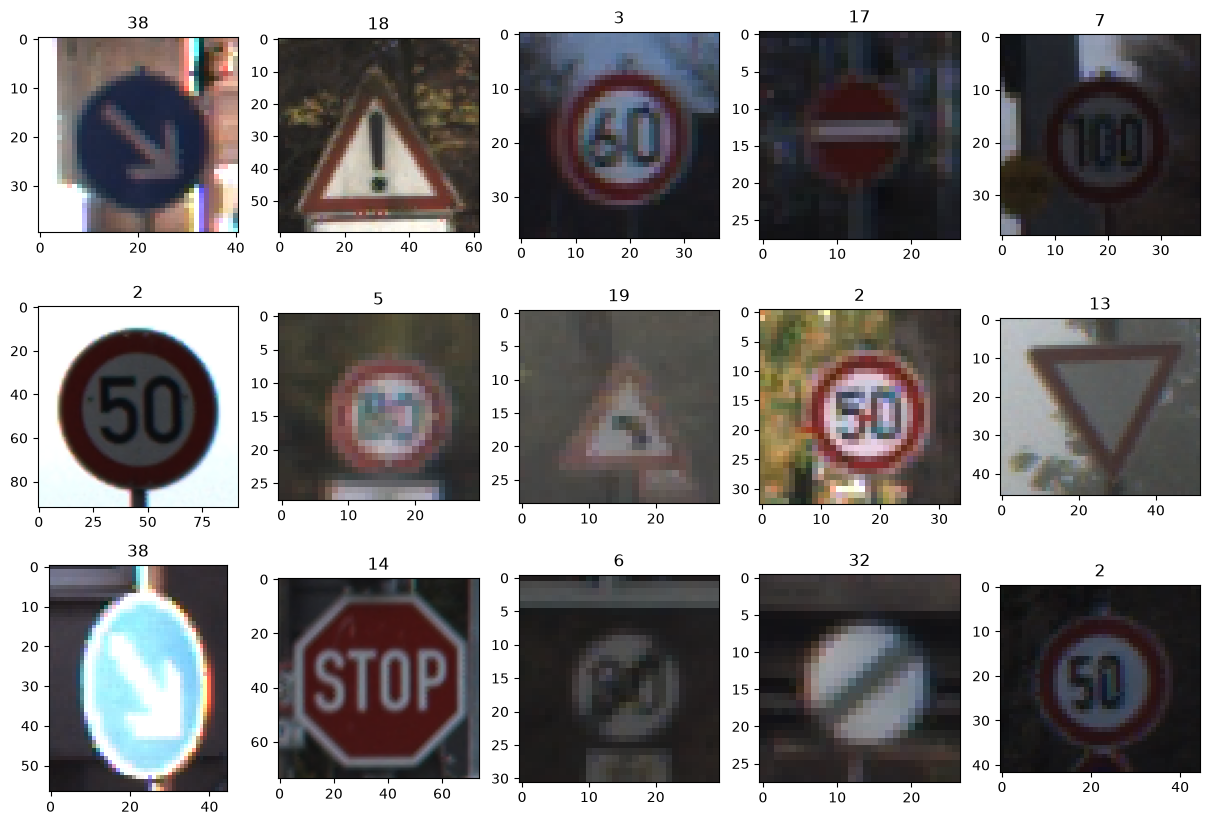

In [5]:
# Load the training labels
root = path
data = pd.read_csv(os.path.join(root, 'Train.csv'))
print(data)
# Number of training samples (amount of samples in data)
num_samples = len(data)
print("Number of samples is: ", num_samples)

# Show random data samples
for ii in range(15):
    # Get random index
    idx = np.random.randint(0, num_samples)
    # Load image
    img = cv2.imread(os.path.join(root, data.iloc[idx]['Path']))
    # Convert image to RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    # Show image
    plt.subplot(3,5,ii+1), plt.imshow(img), plt.title(data.iloc[idx]['ClassId'])

### Step 3

Inspect the dataset by computing and plotting the per-class histogram.

In [6]:
# Extract class identifiers
# Hint: Check the csv 
ids = data['ClassId']
print(ids)

0        20
1        20
2        20
3        20
4        20
         ..
39204    42
39205    42
39206    42
39207    42
39208    42
Name: ClassId, Length: 39209, dtype: int64


Compute the per class histogram. You can use any approach you want (e.g. `numpy`). It's also worth looking at the `Counter` function from the `collections` module ([link](https://docs.python.org/3/library/collections.html#collections.Counter)) ;-)

Counter({2: 2250, 1: 2220, 13: 2160, 12: 2100, 38: 2070, 10: 2010, 4: 1980, 5: 1860, 25: 1500, 9: 1470, 7: 1440, 3: 1410, 8: 1410, 11: 1320, 18: 1200, 35: 1200, 17: 1110, 14: 780, 31: 780, 33: 689, 15: 630, 26: 600, 28: 540, 23: 510, 30: 450, 6: 420, 16: 420, 34: 420, 22: 390, 36: 390, 20: 360, 40: 360, 21: 330, 39: 300, 24: 270, 29: 270, 27: 240, 32: 240, 41: 240, 42: 240, 0: 210, 19: 210, 37: 210})
List of unique classess: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42]
Number of classess in dataset: 43
Most common: class 2 (2250 times)
Least common: class 0 (210 times)
The ideal number of items per class: 911.8372093023256


(Text(0.5, 0, 'Traffic Sign ID'), Text(0, 0.5, 'Counts'))

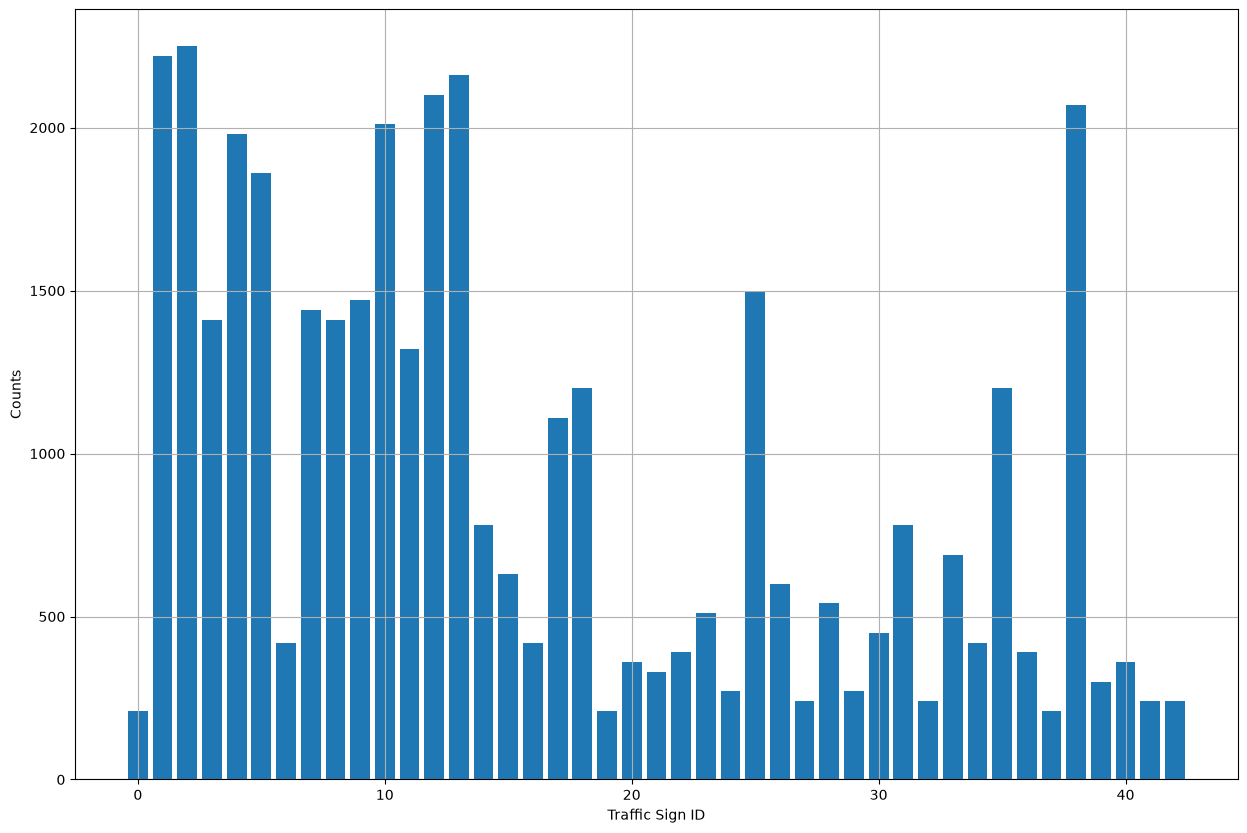

In [7]:
from collections import Counter
hist = Counter(ids)

print(hist)

# just to check for myself for the data set
def data_set_analysis(ids, num_samples):
    unique_ids = ids.unique()
    unique_ids, counts = np.unique(ids, return_counts=True)

    max_idx = np.argmax(counts)
    most_common_id = unique_ids[max_idx]
    max_count_id = counts[max_idx]

    min_idx = np.argmin(counts)
    least_common_id = unique_ids[min_idx]
    min_count_id = counts[min_idx]
    
    print(f"List of unique classess: {unique_ids}")
    print(f"Number of classess in dataset: {len(unique_ids)}")   
    print(f"Most common: class {most_common_id} ({max_count_id} times)")
    print(f"Least common: class {least_common_id} ({min_count_id} times)")
    print(f"The ideal number of items per class: {num_samples / len(unique_ids)}")

    return

data_set_analysis(ids, num_samples)
plt.bar(hist.keys(), hist.values()), plt.grid(True)
plt.xlabel('Traffic Sign ID'), plt.ylabel('Counts')

### Questions

Please answer the following questions:
* Q: Do you consider the dataset to be balanced? If so, why? If not, why?

  A: As we can see from the histogram and additional data I've gathered we can definetelly say that this data set is not balanced, we have non-uniform distribution of items per class, for data set to be balanced we need to have ~911 items per class, so each class will be represented equally.
* Are there any classes that are (significantly) over-represented or under-represeneted?

  A: As we can see from the data set histogram we can say that the set is not balanced at all as I have mentioned above we need to have ~911 per item for it to be considered as balenced in tems of number of elements per class.
  Here we can see how starting from the most common class 2 we have less and less items per class represented.
  2: 2250, 1: 2220, 13: 2160, 12: 2100, 38: 2070, 10: 2010, 4: 1980, 5: 1860, 25: 1500, 9: 1470, 7: 1440, 3: 1410, 8: 1410, 11: 1320, 18: 1200, 35: 1200, 17: 1110
  The sendond part of the list shows the jump in number of samples from 1110 to 780 and it keeps decreasing.
  14: 780, 31: 780, 33: 689, 15: 630, 26: 600, 28: 540, 23: 510, 30: 450, 6: 420, 16: 420, 34: 420, 22: 390, 36: 390, 20: 360, 40: 360, 21: 330, 39: 300, 24: 270, 29: 270, 27: 240, 32: 240, 41: 240, 42: 240, 0: 210, 19: 210, 37: 210}

  The difference between the most represented class and least represented in 2040 samples, the gap is preety huge.

### Optional

Perform a further analysis on the dataset and draw some conclusion from it.

Hint 1: Unlike MNIST or CIFAR10, this dataset contains images with various spatial resolutions. Is there anything we can tell about the resolution distribution?
Hint 2: What about the brightness distribution? Are there classes there are significantly more bright than others?

As we can see from the plottted graph belowe we have a different reolutions of the images in data set present, starting from 31x31 as a most common to the higher resolutions that could be presented only with few items with this reolution.
Regarding the brightness we can see that there are classes that have dark colors i.e. set 42, and most of the classess sit in tange of 50-100 meaning having a low light brightnessand 9 classess with 100 and more brightness meaning they have balanced brightness. It means that this set requires normalization and standartization.

{0: np.float64(122.70056331748485), 1: np.float64(108.08028632650468), 2: np.float64(92.8774944328615), 3: np.float64(67.21730555693492), 4: np.float64(69.44473842365893), 5: np.float64(59.040452147279886), 6: np.float64(40.25042321908886), 7: np.float64(58.48195600544459), 8: np.float64(46.90837800623551), 9: np.float64(92.83680721986902), 10: np.float64(50.39271186318193), 11: np.float64(87.89301844315935), 12: np.float64(89.18930848481466), 13: np.float64(99.2141468678718), 14: np.float64(110.13069980759622), 15: np.float64(100.67564601009234), 16: np.float64(102.82885619870649), 17: np.float64(78.1812967507444), 18: np.float64(95.10385039833506), 19: np.float64(71.51805238417451), 20: np.float64(57.36186685680291), 21: np.float64(83.29062846025165), 22: np.float64(109.74736134081607), 23: np.float64(82.87864046505062), 24: np.float64(81.16490030658578), 25: np.float64(83.3476519816658), 26: np.float64(69.63298549648123), 27: np.float64(76.28523898491689), 28: np.float64(100.1174534

(Text(0.5, 0, 'Traffic Sign ID'), Text(0, 0.5, 'Counts'))

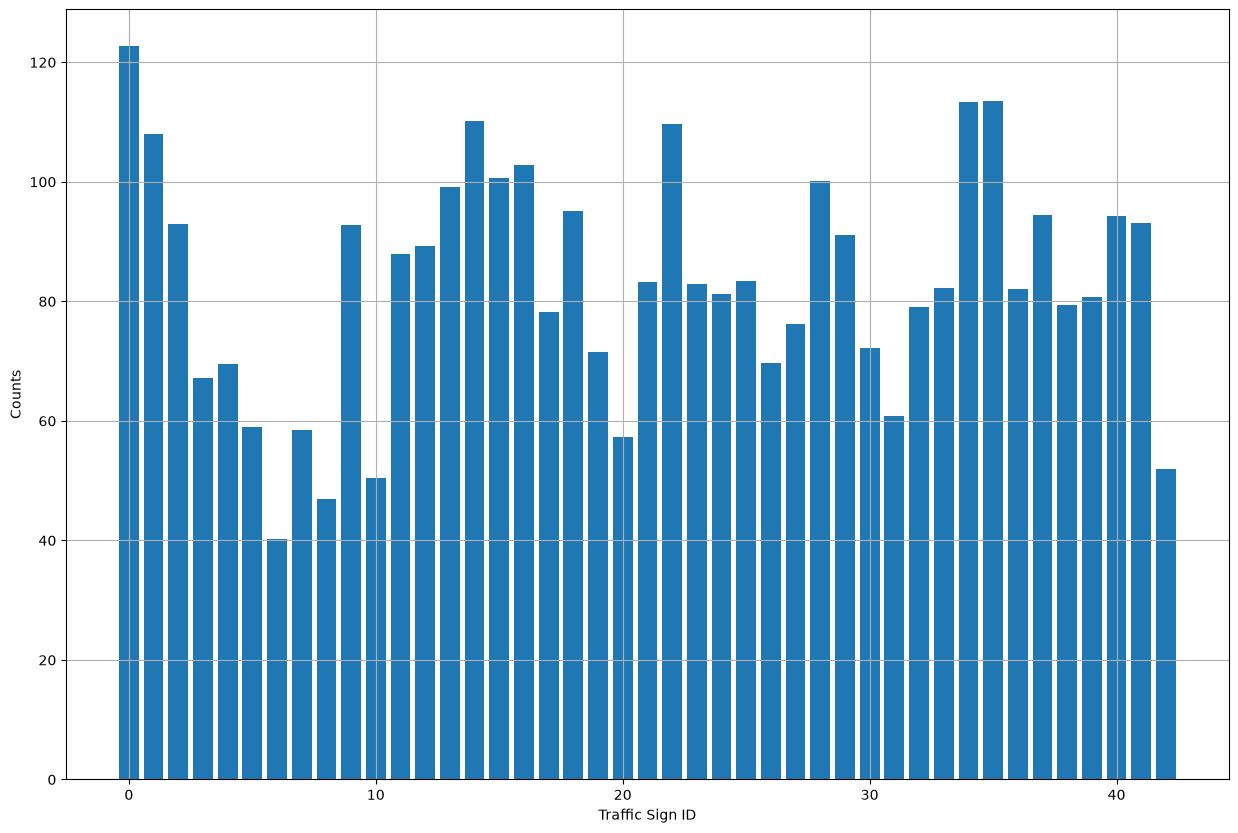

In [10]:
# resolution distribution in the data set
width_height_pairs = list(zip(data['Width'], data['Height']))
resolution_counter = Counter(width_height_pairs)
all_resolutions = resolution_counter.most_common()
counts = [count for (_, h), count in all_resolutions]
labels = [f"{w}x{h}" for (w, h), count in all_resolutions]
plt.figure(figsize=(34, 20))
plt.bar(range(len(counts)), counts, color='firebrick', width=0.8)
plt.title('All Image Resolutions Distribution', fontsize=18, fontweight='bold')
plt.xlabel('Unique Resolution Ranks (Most to Least Frequent)', fontsize=18)
plt.ylabel('Number of Images', fontsize=12)
plt.xticks(range(0, len(labels), 20), [labels[i] for i in range(0, len(labels), 20)], rotation=45, ha='right')
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()

# color distribution in the data set
class_to_paths = data.groupby('ClassId')['Path'].apply(list).to_dict()
class_color_distributions = {}
total_classes = len(class_to_paths)
for i, (class_id, paths) in enumerate(class_to_paths.items(), 1):    
    brightness_values = []
    for path in paths:
        img_path = os.path.join(root, path)
        img = cv2.imread(img_path)
        if img is not None:
            gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
            brightness_values.append(np.mean(gray))
    if brightness_values:
        class_color_distributions[class_id] = np.mean(brightness_values)
print(class_color_distributions)

plt.bar(class_color_distributions.keys(), class_color_distributions.values()), plt.grid(True)
plt.xlabel('Traffic Sign ID'), plt.ylabel('Counts')